In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=44ec175f-b494-4bd4-89b3-5c516b6eba9e
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:04<00:00, 184MB/s]  

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noisy_metadata_v2.csv
    b6000_split.csv
    noise_manifest_v2.json
    noisy_500_v2/
        V/
            00002372_V_500_roll_01.png
            00002426_V_500_roll_07.png
            00002372_V_500_roll_02.png
            00002556_V_500_roll_09.png
            00002376_V_500_roll_08.png
            00002373_V_500_roll_07.png
            00002433_V_500_roll_06.png
            00002596_V_500_roll_01.png
            00002556_V_500_roll_04.png
            00002448_V_500_roll_07.png
            00002586_V_500_roll_04.png
            00002392_V_500_roll_03.png
            00002488_V_500_roll_04.png
            00002435_V_500_roll_05.png
            00002418_V_500_roll_02.png
            00002304_V_500_roll_04.png
            00002352_V_500_roll_10.png
            00002405_V_500_roll_10.png
            00002472_V_500_roll_06.png
            00002405_V_500_roll_05.png
        R/
            00002408_R_500_slap_07.png
            00002391_R_500_slap

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
clean_list.csv
noisy_metadata_v2.csv
b6000_split.csv
noise_manifest_v2.json
clean_500/V/00002372_V_500_roll_01.png
clean_500/V/00002426_V_500_roll_07.png
clean_500/V/00002372_V_500_roll_02.png
clean_500/V/00002556_V_500_roll_09.png
clean_500/V/00002376_V_500_roll_08.png
clean_500/V/00002373_V_500_roll_07.png
clean_500/V/00002433_V_500_roll_06.png
clean_500/V/00002596_V_500_roll_01.png
clean_500/V/00002556_V_500_roll_04.png
clean_500/V/00002448_V_500_roll_07.png
clean_500/V/00002586_V_500_roll_04.png
clean_500/V/00002392_V_500_roll_03.png
clean_500/V/00002488_V_500_roll_04.png
clean_500/V/00002435_V_500_roll_05.png
clean_500/V/00002418_V_500_roll_02.png
clean_500/V/00002304_V_500_roll_04.png
clean_500/V/00002352_V_500_roll_10.png
clean_500/V/00002405_V_500_roll_10.png
clean_500/V/00002472_V_500_roll_06.png
clean_500/V/00002405_V_500_roll_05.png
clean_500/V/00002369_V_500_roll_02.png
clean

In [5]:
import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
!nvidia-smi
!pip -q list 2>/dev/null | grep -i -E "scikit-image|opencv|pandas|nbis"

torch: 2.11.0+cu128 | CUDA: True
Thu Oct 29 10:42:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------

In [12]:
import os, json, time, random, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
try:
    from skimage.metrics import structural_similarity as sk_ssim
except ImportError:
    subprocess.run(["pip", "install", "-q", "scikit-image"])
    from skimage.metrics import structural_similarity as sk_ssim

ROOT = Path("/kaggle/working/dataset/noise_project_v2")
CLEAN_DIR, NOISY_DIR = ROOT/"clean_500", ROOT/"noisy_500_v2"
OUT = Path("/kaggle/working/dnunet"); OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
DEPTH, CH = 5, 32            # nested levels, filters per layer (paper: 32)
CROP, CROPS_PER_IMAGE, BATCH = 256, 2, 8
EPOCHS, LR = 50, 1e-3        # paper: Adam, lr 0.001
LAMBDA, SSIM_WIN = 0.5, 11   # not specified in the paper text; tunable
NUM_WORKERS = 2

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda")
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 Tesla T4


In [13]:
for f in ["clean_list.csv", "noisy_metadata_v2.csv", "b6000_split.csv"]:
    d = pd.read_csv(ROOT/f)
    print(f, d.shape); print(list(d.columns)); display(d.head(3)); print()

clean_list.csv (2490, 31)
['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split', 'clean_path']


,source,key,participant,device,ppi,capture,frgp,finger_name,zip_member,sha256,...,items_9_326,has_class_9_307,class_9_307,has_annotation,nfiq2,valid,nfiq2_bin,quality_group,split,clean_path
0,b,00002302_R_500_slap_01,2302,R,500,slap-segmented,1,R thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,c5ee6ca25aa48b27c25a70bc28c0f15bf99fa55c333fcb...,...,NaN,NaN,NaN,False,81,True,81-100,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...
1,b,00002302_R_500_slap_03,2302,R,500,slap-segmented,3,R middle,sd302b/images/baseline/R/500/slap-segmented/pn...,ce0304e9e35ba73fdd96d16c441e5532175189d4b3a503...,...,NaN,NaN,NaN,False,73,True,61-80,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...
2,b,00002302_R_500_slap_06,2302,R,500,slap-segmented,6,L thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,268e7ab2924ddbbf4bcc964b946443a68103ab97934b99...,...,NaN,NaN,NaN,False,78,True,61-80,clean,train,/content/drive/MyDrive/NIST/noise_project/clea...



noisy_metadata_v2.csv (2490, 17)
['key', 'device', 'split', 'participant', 'frgp', 'has_annotation', 'clean_nfiq2', 'noisy_nfiq2', 'attempts', 'seed_used', 'cfg_used', 'noises', 'overink_strength', 'target', 'kept_above30', 'clean_path', 'noisy_path']


,key,device,split,participant,frgp,has_annotation,clean_nfiq2,noisy_nfiq2,attempts,seed_used,cfg_used,noises,overink_strength,target,kept_above30,clean_path,noisy_path
0,00002546_V_500_roll_05,V,train,2546,5,True,77,25,1,2026,Q2,creases+overink+scratch,1.863,55,False,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...
1,00002449_U_500_roll_02,U,train,2449,2,False,67,11,3,4026,Q2,creases+fragment+overink+smudge+gauss,2.016,10,True,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...
2,00002624_S_500_slap_04,S,val,2624,4,False,87,3,4,5026,STRONG,overink+creases+partial+blur,3.192,55,False,/content/drive/MyDrive/NIST/noise_project/clea...,/content/drive/MyDrive/NIST/noise_project/nois...



b6000_split.csv (6000, 30)
['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split']


,source,key,participant,device,ppi,capture,frgp,finger_name,zip_member,sha256,...,items_9_325,items_9_326,has_class_9_307,class_9_307,has_annotation,nfiq2,valid,nfiq2_bin,quality_group,split
0,b,00002302_R_500_slap_01,2302,R,500,slap-segmented,1,R thumb,sd302b/images/baseline/R/500/slap-segmented/pn...,c5ee6ca25aa48b27c25a70bc28c0f15bf99fa55c333fcb...,...,NaN,NaN,NaN,NaN,False,81,True,81-100,clean,train
1,b,00002302_R_500_slap_02,2302,R,500,slap-segmented,2,R index,sd302b/images/baseline/R/500/slap-segmented/pn...,84d65767e492d22536405376447a883db476482c4ab664...,...,NaN,NaN,NaN,NaN,False,55,True,41-60,middle,train
2,b,00002302_R_500_slap_03,2302,R,500,slap-segmented,3,R middle,sd302b/images/baseline/R/500/slap-segmented/pn...,ce0304e9e35ba73fdd96d16c441e5532175189d4b3a503...,...,NaN,NaN,NaN,NaN,False,73,True,61-80,clean,train


In [14]:
rows = []
for p in sorted(CLEAN_DIR.rglob("*.png")):
    rel = p.relative_to(CLEAN_DIR); n = NOISY_DIR/rel
    if n.exists():
        rows.append(dict(rel=str(rel), stem=p.stem, ftype=rel.parts[0],
                         participant=int(p.stem.split("_")[0]),
                         clean=str(p), noisy=str(n)))
pairs = pd.DataFrame(rows)
print("pairs found:", len(pairs))

sp = pd.read_csv(ROOT/"b6000_split.csv")
sp.columns = [c.strip().lower() for c in sp.columns]
sp["split"] = (sp["split"].astype(str).str.strip().str.lower()
               .replace({"validation": "val", "valid": "val", "training": "train"}))

if "key" in sp.columns and sp["key"].astype(str).isin(pairs.stem).mean() > 0.9:
    pairs["split"] = pairs.stem.map(dict(zip(sp["key"].astype(str), sp["split"])))
    print("split mapped by 'key'")
else:
    sp["participant"] = pd.to_numeric(sp["participant"], errors="coerce")
    sp = sp.dropna(subset=["participant"]); sp["participant"] = sp["participant"].astype(int)
    assert sp.groupby("participant")["split"].nunique().max() == 1, "a participant is in >1 split"
    pairs["split"] = pairs.participant.map(sp.drop_duplicates("participant").set_index("participant")["split"])
    print("split mapped by 'participant'")

print(pairs.split.value_counts(dropna=False))
pairs = pairs.dropna(subset=["split"])
assert pairs.groupby("participant")["split"].nunique().max() == 1
train_df, val_df, test_df = [pairs[pairs.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]
print("train/val/test:", len(train_df), len(val_df), len(test_df))

# shape sanity check: noisy and clean must be pixel-aligned
bad = 0
for r in pairs.sample(min(100, len(pairs)), random_state=0).itertuples():
    a, b = cv2.imread(r.noisy, 0), cv2.imread(r.clean, 0)
    bad += a.shape != b.shape
print("shape mismatches in 100-pair sample:", bad)
print("example size:", cv2.imread(train_df.clean[0], 0).shape)

pairs found: 2490
split mapped by 'participant'
split
train    1764
val       388
test      338
Name: count, dtype: int64
train/val/test: 1764 388 338
shape mismatches in 100-pair sample: 0
example size: (574, 352)


In [15]:
class TrainDS(Dataset):
    def __init__(self, df, reps): self.df, self.reps = df.reset_index(drop=True), reps
    def __len__(self): return len(self.df) * self.reps
    def __getitem__(self, i):
        r = self.df.iloc[i % len(self.df)]
        n = cv2.imread(r.noisy, cv2.IMREAD_GRAYSCALE); c = cv2.imread(r.clean, cv2.IMREAD_GRAYSCALE)
        H, W = n.shape
        ph, pw = max(0, CROP - H), max(0, CROP - W)
        if ph or pw:
            n = cv2.copyMakeBorder(n, 0, ph, 0, pw, cv2.BORDER_REFLECT_101)
            c = cv2.copyMakeBorder(c, 0, ph, 0, pw, cv2.BORDER_REFLECT_101)
            H, W = n.shape
        y, x = random.randint(0, H - CROP), random.randint(0, W - CROP)
        n, c = n[y:y+CROP, x:x+CROP], c[y:y+CROP, x:x+CROP]
        if random.random() < 0.5: n, c = n[:, ::-1], c[:, ::-1]
        f = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float().div(255).unsqueeze(0)
        return f(n), f(c)

class EvalDS(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        n = cv2.imread(r.noisy, cv2.IMREAD_GRAYSCALE); c = cv2.imread(r.clean, cv2.IMREAD_GRAYSCALE)
        f = lambda a: torch.from_numpy(a).float().div(255).unsqueeze(0)
        return f(n), f(c), i

train_loader = DataLoader(TrainDS(train_df, CROPS_PER_IMAGE), batch_size=BATCH, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True, persistent_workers=True)
val_loader  = DataLoader(EvalDS(val_df),  batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(EvalDS(test_df), batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
print(len(train_loader), "train iters/epoch")

441 train iters/epoch


In [16]:
class Conv5(nn.Module):                       # 5x5 conv + ReLU
    def __init__(s, i, o): super().__init__(); s.c = nn.Conv2d(i, o, 5, padding=2)
    def forward(s, x): return F.relu(s.c(x), inplace=True)

class Down(nn.Module):                        # learned 2x2, stride 2 (replaces max-pool)
    def __init__(s, c): super().__init__(); s.c = nn.Conv2d(c, c, 2, stride=2)
    def forward(s, x): return F.relu(s.c(x), inplace=True)

class Up(nn.Module):                          # learned 2x2, stride 2 (replaces up-sampling)
    def __init__(s, c): super().__init__(); s.c = nn.ConvTranspose2d(c, c, 2, stride=2)
    def forward(s, x): return F.relu(s.c(x), inplace=True)

class DeepNestedUNet(nn.Module):
    """Nested U-Nets + dense skips: node X[i,j] takes ALL same-level nodes X[i,0..j-1]
    plus the up-sampled X[i+1,j-1]. Output is read from X[0,depth-1]."""
    def __init__(s, in_ch=1, ch=32, depth=5):
        super().__init__()
        s.depth = depth
        s.stem = Conv5(in_ch, ch)
        s.down = nn.ModuleList([Down(ch) for _ in range(depth - 1)])
        s.enc  = nn.ModuleList([Conv5(ch, ch) for _ in range(depth - 1)])
        s.up, s.node = nn.ModuleDict(), nn.ModuleDict()
        for j in range(1, depth):
            for i in range(depth - j):
                s.up[f"{i}_{j}"]   = Up(ch)
                s.node[f"{i}_{j}"] = Conv5(ch * (j + 1), ch)
        s.out = nn.Conv2d(ch, 1, 5, padding=2)

    def forward(s, inp):
        x = {(0, 0): s.stem(inp)}
        for i in range(1, s.depth):
            x[(i, 0)] = s.enc[i-1](s.down[i-1](x[(i-1, 0)]))
        for j in range(1, s.depth):
            for i in range(s.depth - j):
                feats = [x[(i, k)] for k in range(j)] + [s.up[f"{i}_{j}"](x[(i+1, j-1)])]
                x[(i, j)] = s.node[f"{i}_{j}"](torch.cat(feats, 1))
        return torch.sigmoid(s.out(x[(0, s.depth - 1)]))

m = DeepNestedUNet(1, CH, DEPTH).to(device)
print("params: %.2f M" % (sum(p.numel() for p in m.parameters()) / 1e6))
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    print(m(torch.zeros(1, 1, 256, 256, device=device)).shape)
del m; torch.cuda.empty_cache()

params: 0.93 M
torch.Size([1, 1, 256, 256])


In [17]:
def ssim_torch(x, y, win=SSIM_WIN):           # local SSIM, c1=(0.01)^2, c2=(0.03)^2, l=1 (as in the paper)
    c1, c2 = 0.01**2, 0.03**2
    mx, my = F.avg_pool2d(x, win, 1), F.avg_pool2d(y, win, 1)
    sxx = F.avg_pool2d(x*x, win, 1) - mx*mx
    syy = F.avg_pool2d(y*y, win, 1) - my*my
    sxy = F.avg_pool2d(x*y, win, 1) - mx*my
    return (((2*mx*my + c1) * (2*sxy + c2)) / ((mx*mx + my*my + c1) * (sxx + syy + c2))).mean()

def enhance_loss(p, t):                       # lambda*(1-SSIM) + (1-lambda)*MSE
    p, t = p.float(), t.float()
    return LAMBDA * (1 - ssim_torch(p, t)) + (1 - LAMBDA) * F.mse_loss(p, t)

def to_u8(t): return (t.squeeze().detach().cpu().numpy() * 255).round().clip(0, 255).astype(np.uint8)

def metrics_u8(pred, gt):                     # 0-255 scale, per image
    d = pred.astype(np.float64) - gt.astype(np.float64)
    rmse = float(np.sqrt((d**2).mean()))
    psnr = 20 * np.log10(255 / rmse) if rmse > 0 else 100.0
    ssim = float(sk_ssim(gt, pred, data_range=255))   # skimage default 7x7 uniform window
    return rmse, psnr, ssim

@torch.no_grad()
def predict_full(model, x):
    H, W = x.shape[-2:]; m = 2 ** (DEPTH - 1)
    xp = F.pad(x, (0, (-W) % m, 0, (-H) % m), mode="reflect")
    with torch.autocast("cuda", dtype=torch.float16):
        y = model(xp)
    return y[..., :H, :W].float().clamp(0, 1)

In [18]:
model = DeepNestedUNet(1, CH, DEPTH).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)  # my addition
scaler = torch.amp.GradScaler("cuda")
LAST, BEST = OUT/"last.pt", OUT/"best.pt"
hist, start, best_psnr = [], 0, -1.0

if LAST.exists():                              # resume after a crash / session restart
    ck = torch.load(LAST, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    hist, start, best_psnr = ck["hist"], ck["epoch"] + 1, ck["best"]
    print("resumed from epoch", start)

for ep in range(start, EPOCHS):
    t0 = time.time(); model.train(); tl, n = 0.0, 0
    for x, y in tqdm(train_loader, leave=False, desc=f"epoch {ep+1}"):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(x)
        loss = enhance_loss(p, y)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        tl += loss.item() * x.size(0); n += x.size(0)

    model.eval(); vl, R, P, S = 0.0, [], [], []
    for x, y, _ in val_loader:
        x, y = x.to(device), y.to(device)
        p = predict_full(model, x)
        vl += enhance_loss(p, y).item()
        r, ps, s = metrics_u8(to_u8(p), to_u8(y)); R.append(r); P.append(ps); S.append(s)
    rec = dict(epoch=ep+1, train_loss=tl/n, val_loss=vl/len(val_loader), val_rmse=np.mean(R),
               val_psnr=np.mean(P), val_ssim=np.mean(S), lr=opt.param_groups[0]["lr"], sec=time.time()-t0)
    hist.append(rec); sched.step(rec["val_psnr"])
    if rec["val_psnr"] > best_psnr:
        best_psnr = rec["val_psnr"]; torch.save(model.state_dict(), BEST)
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    hist=hist, epoch=ep, best=best_psnr), LAST)
    json.dump(hist, open(OUT/"history.json", "w"))
    print(f"ep {ep+1:02d} | train {rec['train_loss']:.4f} | val {rec['val_loss']:.4f} | "
          f"RMSE {rec['val_rmse']:.2f} PSNR {rec['val_psnr']:.2f} SSIM {rec['val_ssim']:.4f} | {rec['sec']:.0f}s")

epoch 1:   0%|          | 0/441 [00:00<?, ?it/s]

ep 01 | train 0.1508 | val 0.1158 | RMSE 46.83 PSNR 15.12 SSIM 0.7992 | 116s


epoch 2:   0%|          | 0/441 [00:00<?, ?it/s]

ep 02 | train 0.1186 | val 0.0988 | RMSE 44.23 PSNR 15.55 SSIM 0.8272 | 113s


epoch 3:   0%|          | 0/441 [00:00<?, ?it/s]

ep 03 | train 0.1085 | val 0.0784 | RMSE 38.43 PSNR 16.77 SSIM 0.8603 | 113s


... (90 outputs left out)

epoch 49:   0%|          | 0/441 [00:00<?, ?it/s]

ep 49 | train 0.0467 | val 0.0390 | RMSE 24.67 PSNR 20.72 SSIM 0.9263 | 114s


epoch 50:   0%|          | 0/441 [00:00<?, ?it/s]

ep 50 | train 0.0470 | val 0.0393 | RMSE 25.17 PSNR 20.52 SSIM 0.9261 | 114s


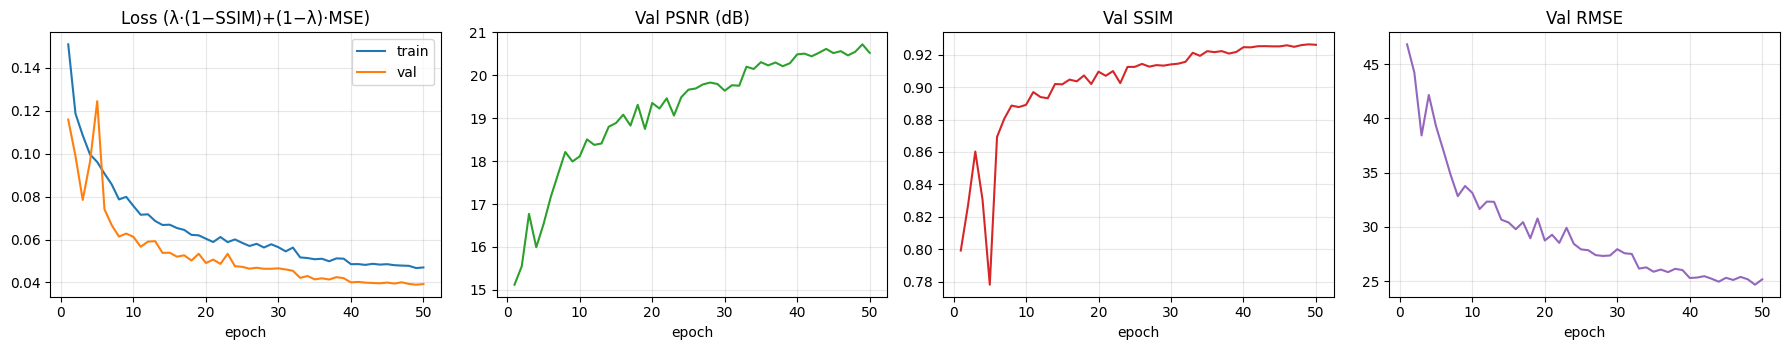

In [19]:
h = pd.DataFrame(json.load(open(OUT/"history.json")))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss (λ·(1−SSIM)+(1−λ)·MSE)"); ax[0].legend()
ax[1].plot(h.epoch, h.val_psnr, c="C2"); ax[1].set_title("Val PSNR (dB)")
ax[2].plot(h.epoch, h.val_ssim, c="C3"); ax[2].set_title("Val SSIM")
ax[3].plot(h.epoch, h.val_rmse, c="C4"); ax[3].set_title("Val RMSE")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT/"training_curves.png", dpi=150); plt.show()

In [20]:
model = DeepNestedUNet(1, CH, DEPTH).to(device)
model.load_state_dict(torch.load(BEST, map_location=device)); model.eval()

ENH, NZ, CL = OUT/"enhanced_test", OUT/"nfiq_in/noisy", OUT/"nfiq_in/clean"
NF_ENH = OUT/"nfiq_in/enhanced"
for d in [ENH, NZ, CL, NF_ENH]: d.mkdir(parents=True, exist_ok=True)

recs = []
for x, y, i in tqdm(test_loader):
    r = test_df.iloc[int(i)]
    p = predict_full(model, x.to(device))
    pu, nu, cu = to_u8(p), to_u8(x), to_u8(y)
    nr, np_, ns = metrics_u8(nu, cu); er, ep_, es = metrics_u8(pu, cu)
    recs.append(dict(stem=r.stem, ftype=r.ftype, participant=r.participant,
                     noisy_rmse=nr, noisy_psnr=np_, noisy_ssim=ns,
                     enh_rmse=er, enh_psnr=ep_, enh_ssim=es))
    cv2.imwrite(str(ENH/f"{r.stem}.png"), pu); cv2.imwrite(str(NF_ENH/f"{r.stem}.png"), pu)
    cv2.imwrite(str(NZ/f"{r.stem}.png"), nu);   cv2.imwrite(str(CL/f"{r.stem}.png"), cu)

res = pd.DataFrame(recs); res.to_csv(OUT/"test_results.csv", index=False)
print(res[["noisy_rmse","enh_rmse","noisy_psnr","enh_psnr","noisy_ssim","enh_ssim"]].mean().round(4))

  0%|          | 0/338 [00:00<?, ?it/s]

noisy_rmse    57.5999
enh_rmse      24.6801
noisy_psnr    13.2875
enh_psnr      20.7338
noisy_ssim     0.6716
enh_ssim       0.9251
dtype: float64


In [21]:
NFIQ2_BIN = shutil.which("NFIQ2") or shutil.which("nfiq2")
print("NFIQ2 binary:", NFIQ2_BIN)
if NFIQ2_BIN:
    r = subprocess.run([NFIQ2_BIN, "--help"], capture_output=True, text=True)
    print((r.stdout + r.stderr)[:1000])
else:
    print("NFIQ 2 not found. Install the NIST NFIQ 2 release (github.com/usnistgov/NFIQ2) "
          "so that the 'NFIQ2' command is on PATH, then re-run this cell.")

NFIQ2 binary: None
NFIQ 2 not found. Install the NIST NFIQ 2 release (github.com/usnistgov/NFIQ2) so that the 'NFIQ2' command is on PATH, then re-run this cell.


In [22]:
import requests

rel = requests.get("https://api.github.com/repos/usnistgov/NFIQ2/releases/latest", timeout=30).json()
print("release:", rel["tag_name"])
for a in rel["assets"]:
    print("  ", a["name"])

debs = [a for a in rel["assets"] if a["name"].endswith(".deb")
        and not any(k in a["name"].lower() for k in ("arm64", "armhf"))]
print("\ncandidate .deb files:", [a["name"] for a in debs])

release: v2.3.0
   nfiq2-2.3.0-macos.pkg
   nfiq2-2.3.0-win32.msi
   nfiq2-2.3.0-win64.msi
   nfiq2-dev_2.3.0-1_rpos12_arm64.deb
   nfiq2-dev_2.3.0-1_ubuntu20_amd64.deb
   nfiq2-dev_2.3.0-1_ubuntu22_amd64.deb
   nfiq2-dev_2.3.0-1_ubuntu24_amd64.deb
   nfiq2_2.3.0-1_rpos12_arm64.deb
   nfiq2_2.3.0-1_ubuntu20_amd64.deb
   nfiq2_2.3.0-1_ubuntu22_amd64.deb
   nfiq2_2.3.0-1_ubuntu24_amd64.deb

candidate .deb files: ['nfiq2-dev_2.3.0-1_ubuntu20_amd64.deb', 'nfiq2-dev_2.3.0-1_ubuntu22_amd64.deb', 'nfiq2-dev_2.3.0-1_ubuntu24_amd64.deb', 'nfiq2_2.3.0-1_ubuntu20_amd64.deb', 'nfiq2_2.3.0-1_ubuntu22_amd64.deb', 'nfiq2_2.3.0-1_ubuntu24_amd64.deb']


In [23]:
url = debs[0]["browser_download_url"]
!wget -q "{url}" -O /tmp/nfiq2.deb
!apt-get install -y /tmp/nfiq2.deb 2>&1 | tail -n 15

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  nfiq2-dev
0 upgraded, 1 newly installed, 0 to remove and 174 not upgraded.
Need to get 0 B/12.2 MB of archives.
After this operation, 48.6 MB of additional disk space will be used.
Get:1 /tmp/nfiq2.deb nfiq2-dev amd64 2.3.0-1 [12.2 MB]
Selecting previously unselected package nfiq2-dev.
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack /tmp/nfiq2.deb ...
Unpacking nfiq2-dev (2.3.0-1) ...
Setting up nfiq2-dev (2.3.0-1) ...


In [24]:
NFIQ2_BIN = shutil.which("nfiq2") or shutil.which("NFIQ2") or ("/usr/local/bin/nfiq2" if os.path.exists("/usr/local/bin/nfiq2") else None)
print("NFIQ2 binary:", NFIQ2_BIN)
if NFIQ2_BIN:
    r = subprocess.run([NFIQ2_BIN, "--help"], capture_output=True, text=True)
    print((r.stdout + r.stderr)[:1200])

NFIQ2 binary: None


In [28]:
import shutil, os, subprocess, glob

print("on PATH:", shutil.which("nfiq2"), shutil.which("NFIQ2"))
print("/tmp/nfiq2.deb exists:", os.path.exists("/tmp/nfiq2.deb"))
print("known locations:", [p for p in ["/usr/local/bin/nfiq2", "/usr/bin/nfiq2"] if os.path.exists(p)])
print("anywhere:", glob.glob("/usr/**/nfiq2*", recursive=True)[:10])

# did dpkg register it, and are dependencies missing?
print(subprocess.run("dpkg -l | grep -i nfiq", shell=True, capture_output=True, text=True).stdout or "not installed per dpkg")
print(subprocess.run("cat /etc/os-release | head -n 3", shell=True, capture_output=True, text=True).stdout)

on PATH: None None
/tmp/nfiq2.deb exists: True
known locations: []
anywhere: ['/usr/local/nfiq2', '/usr/local/nfiq2/include/nfiq2_fingerprintimagedata.hpp', '/usr/local/nfiq2/include/nfiq2api.h', '/usr/local/nfiq2/include/nfiq2_data.hpp', '/usr/local/nfiq2/include/nfiq2_algorithm.hpp', '/usr/local/nfiq2/include/nfiq2.hpp', '/usr/local/nfiq2/include/nfiq2_exception.hpp', '/usr/local/nfiq2/include/nfiq2_version.hpp', '/usr/local/nfiq2/include/nfiq2_timer.hpp', '/usr/local/nfiq2/include/nfiq2_qualitymeasures.hpp']
ii  nfiq2-dev                          2.3.0-1                              amd64        NIST Fingerprint Image Quality 2 algorithm

PRETTY_NAME="Ubuntu 24.04.1 LTS"
NAME="Ubuntu"
VERSION_ID="24.04"



In [29]:
print([a["name"] for a in debs])          # check that a non-"-dev" .deb is in this list

cli = [a for a in debs if "dev" not in a["name"].lower()]
print("CLI candidates:", [a["name"] for a in cli])

['nfiq2-dev_2.3.0-1_ubuntu20_amd64.deb', 'nfiq2-dev_2.3.0-1_ubuntu22_amd64.deb', 'nfiq2-dev_2.3.0-1_ubuntu24_amd64.deb', 'nfiq2_2.3.0-1_ubuntu20_amd64.deb', 'nfiq2_2.3.0-1_ubuntu22_amd64.deb', 'nfiq2_2.3.0-1_ubuntu24_amd64.deb']
CLI candidates: ['nfiq2_2.3.0-1_ubuntu20_amd64.deb', 'nfiq2_2.3.0-1_ubuntu22_amd64.deb', 'nfiq2_2.3.0-1_ubuntu24_amd64.deb']


In [30]:
cli24 = next(a for a in debs if a["name"] == "nfiq2_2.3.0-1_ubuntu24_amd64.deb")
url = cli24["browser_download_url"]
!wget -q "{url}" -O /tmp/nfiq2_cli.deb
!apt-get install -y /tmp/nfiq2_cli.deb

NFIQ2_BIN = shutil.which("nfiq2") or next((p for p in ["/usr/local/bin/nfiq2", "/usr/bin/nfiq2"] if os.path.exists(p)), None)
print("NFIQ2 binary:", NFIQ2_BIN)
if NFIQ2_BIN:
    r = subprocess.run([NFIQ2_BIN, "--help"], capture_output=True, text=True)
    print((r.stdout + r.stderr)[:1500])

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'nfiq2' instead of '/tmp/nfiq2_cli.deb'
The following additional packages will be installed:
  libdb5.3++t64
The following NEW packages will be installed:
  libdb5.3++t64 nfiq2
0 upgraded, 2 newly installed, 0 to remove and 174 not upgraded.
Need to get 767 kB/8,957 kB of archives.
After this operation, 63.6 MB of additional disk space will be used.
Get:1 /tmp/nfiq2_cli.deb nfiq2 amd64 2.3.0-1 [8,190 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libdb5.3++t64 amd64 5.3.28+dfsg2-7 [767 kB]
Fetched 767 kB in 1s (1,205 kB/s)                      
Selecting previously unselected package libdb5.3++t64:amd64.
(Reading database ... 130004 files and directories currently installed.)
Preparing to unpack .../libdb5.3++t64_5.3.28+dfsg2-7_amd64.deb ...
Unpacking libdb5.3++t64:amd64 (5.3.28+dfsg2-7) ...
Selecting previously unselected package nfiq2.
Preparing to unpack /tmp

In [32]:
def run_nfiq2(folder, tag):
    out_csv = OUT/f"nfiq2_{tag}.csv"
    if not out_csv.exists():
        cmd = [NFIQ2_BIN, "-F", "-j", "4", "-v", "-i", str(folder), "-o", str(out_csv)]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if not out_csv.exists():
            print(r.stdout[-1500:], r.stderr[-1500:])
            raise RuntimeError("NFIQ2 produced no CSV")
    d = pd.read_csv(out_csv)
    print(tag, "-> raw columns:", list(d.columns)); display(d.head(3))
    fcol = next(c for c in d.columns if "name" in c.lower() or "file" in c.lower())
    scol = next(c for c in d.columns if "quality" in c.lower() or "nfiq" in c.lower())
    s = pd.to_numeric(d[scol], errors="coerce").where(lambda v: (v >= 0) & (v <= 100))
    return pd.Series(s.values, index=d[fcol].map(lambda f: Path(str(f)).stem), name=f"nfiq2_{tag}")

In [35]:
def run_nfiq2(folder, tag):
    out_csv = OUT/f"nfiq2_{tag}.csv"
    if not out_csv.exists():
        cmd = [NFIQ2_BIN, "-F", "-j", "4", "-v", "-i", str(folder), "-o", str(out_csv)]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if not out_csv.exists():
            print(r.stdout[-1500:], r.stderr[-1500:])
            raise RuntimeError("NFIQ2 produced no CSV")
    d = pd.read_csv(out_csv)
    print(tag, "-> raw columns:", list(d.columns)); display(d.head(3))
    fcol = next(c for c in d.columns if "name" in c.lower() or "file" in c.lower())
    scol = next(c for c in d.columns if "quality" in c.lower() or "nfiq" in c.lower())
    s = pd.to_numeric(d[scol], errors="coerce").where(lambda v: (v >= 0) & (v <= 100))
    return pd.Series(s.values, index=d[fcol].map(lambda f: Path(str(f)).stem), name=f"nfiq2_{tag}")

In [36]:
!rm -f /kaggle/working/dnunet/nfiq2_*.csv

In [38]:
assert NFIQ2_BIN, "NFIQ2_BIN is not set: re-run the cell that finds /usr/local/bin/nfiq2"

res = pd.read_csv(OUT/"test_results.csv")
for folder, tag in [(NZ, "noisy"), (CL, "clean"), (NF_ENH, "enh")]:
    sc = run_nfiq2(folder, tag)
    res[f"nfiq2_{tag}"] = res.stem.map(sc)
    print(tag, "-> scored:", res[f"nfiq2_{tag}"].notna().sum(), "| failed/invalid:", res[f"nfiq2_{tag}"].isna().sum())
    print()

res.to_csv(OUT/"test_results.csv", index=False)
print(res[["nfiq2_noisy", "nfiq2_enh", "nfiq2_clean"]].describe().round(2))

 InvalidArgumentError: User cannot use threading flag for single-threaded operations. 
Batch files and recordstores are the only multi-threaded operations.



RuntimeError: NFIQ2 produced no CSV

In [39]:
def run_nfiq2(folder, tag):
    out_csv = OUT/f"nfiq2_{tag}.csv"
    if not out_csv.exists():
        cmd = [NFIQ2_BIN, "-F", "-j", "4", "-v", "-i", str(folder), "-o", str(out_csv)]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if not out_csv.exists():
            print(r.stdout[-1500:], r.stderr[-1500:])
            raise RuntimeError("NFIQ2 produced no CSV")
    d = pd.read_csv(out_csv)
    print(tag, "-> raw columns:", list(d.columns)); display(d.head(3))
    fcol = next(c for c in d.columns if "name" in c.lower() or "file" in c.lower())
    scol = next(c for c in d.columns if "quality" in c.lower() or "nfiq" in c.lower())
    s = pd.to_numeric(d[scol], errors="coerce").where(lambda v: (v >= 0) & (v <= 100))
    return pd.Series(s.values, index=d[fcol].map(lambda f: Path(str(f)).stem), name=f"nfiq2_{tag}")

In [40]:
res = pd.read_csv(OUT/"test_results.csv")
has_nf = "nfiq2_enh" in res.columns
def ms(c): return f"{res[c].mean():.3f} ± {res[c].std():.3f}"
summ = pd.DataFrame({
    "Noisy":    [ms("noisy_rmse"), ms("noisy_psnr"), ms("noisy_ssim")] + ([ms("nfiq2_noisy")] if has_nf else []),
    "Enhanced": [ms("enh_rmse"),   ms("enh_psnr"),   ms("enh_ssim")]   + ([ms("nfiq2_enh")]   if has_nf else []),
}, index=["RMSE ↓", "PSNR (dB) ↑", "SSIM ↑"] + (["NFIQ2 ↑"] if has_nf else []))
if has_nf: summ["Clean (reference)"] = ["-", "-", "-", ms("nfiq2_clean")]
display(summ)
print("images with PSNR improved: %.1f%%" % (100 * (res.enh_psnr > res.noisy_psnr).mean()))
display(res.groupby("ftype")[["noisy_psnr","enh_psnr","noisy_ssim","enh_ssim","noisy_rmse","enh_rmse"]
        + (["nfiq2_noisy","nfiq2_enh","nfiq2_clean"] if has_nf else [])].mean().round(3))
summ.to_csv(OUT/"summary.csv")

,Noisy,Enhanced,Clean (reference)
RMSE ↓,57.600 ± 16.729,24.680 ± 8.015,-
PSNR (dB) ↑,13.288 ± 2.542,20.734 ± 2.825,-
SSIM ↑,0.672 ± 0.145,0.925 ± 0.049,-
NFIQ2 ↑,nan ± nan,nan ± nan,nan ± nan


images with PSNR improved: 100.0%


,noisy_psnr,enh_psnr,noisy_ssim,enh_ssim,noisy_rmse,enh_rmse,nfiq2_noisy,nfiq2_enh,nfiq2_clean
ftype,,,,,,,,,
R,11.091,18.520,0.558,0.888,72.445,31.212,NaN,NaN,NaN
S,11.906,19.445,0.586,0.900,66.689,28.169,NaN,NaN,NaN
U,14.728,22.088,0.766,0.949,48.003,20.797,NaN,NaN,NaN
V,14.652,22.115,0.732,0.950,48.489,20.822,NaN,NaN,NaN
